# Notebook 6 — RF and synchrotron radiation

Install an RF cavity in one of the saved rings, enable mean synchrotron radiation, observe transverse and longitudinal damping, and inspect the closed-orbit momentum deviation $\delta=(p-p_0)/p_0$ along the ring. For these ultrarelativistic electrons, this also describes the relative energy variation to a very good approximation.

## Your tasks

1. Load `ring_dba.json` or `ring_fodo.json`.
2. Install a **1 MV** cavity halfway around the ring. Use harmonic number **400**, so the RF frequency is an integer multiple of the revolution frequency.
3. Calculate the 6D optics without radiation, then enable mean radiation and recalculate the periodic orbit and optics.
4. Plot $\delta$ versus $s$ over the full ring. Identify where particles lose and regain energy.
5. Give a particle small horizontal, vertical, and momentum offsets from the radiating closed orbit. Track for three times the slowest damping time and plot x, y, and delta versus turn.
6. Repeat for the other ring. Compare the energy loss per turn and damping times.

We use the [Xsuite mean-radiation model](https://xsuite.readthedocs.io/en/latest/synchrotron_radiation.html): deterministic energy loss without random photon emission. The 6D closed-orbit calculation finds the synchronous arrival time at the cavity.

### Load a matched ring

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import c
import xtrack as xt

In [2]:
lattice_file = 'ring_dba.json'  # Or 'ring_fodo.json'
line = xt.load(lattice_file)

Loading line from dict:   0%|          | 0/209 [00:00<?, ?it/s]

Done loading line from dict.           


### Install the cavity

Set $f_{\mathrm{RF}}=h\beta_0 c/C$. The chosen voltage exceeds the energy loss per turn for both rings. With the Xsuite phase convention used here, `phase=np.pi` gives the stable zero-gain synchronous phase without radiation for these lattices. When radiation is enabled, the synchronous arrival time shifts so that the cavity restores the lost energy.

In [3]:
harmonic_number = 400
rf_voltage = 1e6  # [V]
f_rev = line.particle_ref.beta0[0] * c / line.get_length()
f_rf = harmonic_number * f_rev
s_rf = line.get_length() / 2

line.insert('rf', xt.Cavity(voltage=rf_voltage, frequency=f_rf, phase=np.pi),
            at=s_rf)
print(f'RF frequency: {f_rf / 1e6:.3f} MHz')

Slicing line:   0%|          | 0/384 [00:00<?, ?it/s]

RF frequency: 499.654 MHz


### 6D optics without radiation

In [4]:
tw_no_rad = line.twiss(method='6d')
print(f'Synchrotron tune without radiation: {tw_no_rad.qs:.5f}')

Synchrotron tune without radiation: 0.00522


### Enable mean radiation and find the periodic solution

In [5]:
line.configure_radiation(model='mean')
tw_rad = line.twiss(method='6d', radiation_analysis=True)
print(f'Energy loss with radiation: {tw_rad.energy_loss / 1e3:.3f} keV/turn')
print(f'Synchrotron tune with radiation: {tw_rad.qs:.5f}')

Energy loss with radiation: 170.674 keV/turn
Synchrotron tune with radiation: 0.00518


### Momentum sawtooth around the ring

The periodic solution loses momentum in the bends and gains it at the cavity. The momentum at the end of a turn returns to its initial value. Compare the radiating orbit with the constant-momentum orbit without radiation.

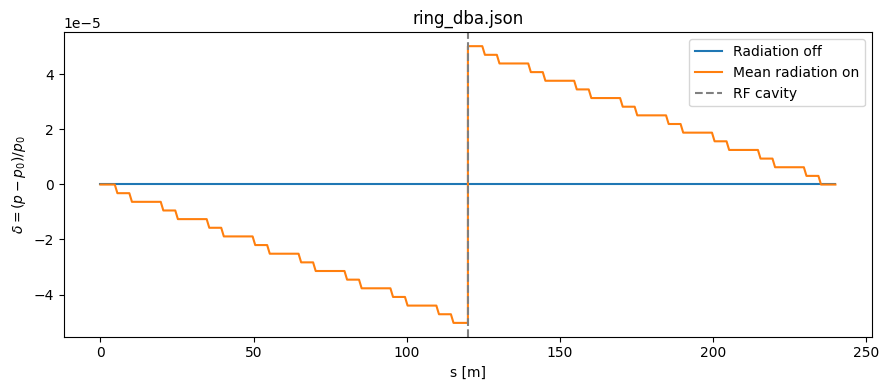

In [6]:
plt.figure(figsize=(9, 4))
plt.plot(tw_no_rad.s, tw_no_rad.delta, label='Radiation off')
plt.plot(tw_rad.s, tw_rad.delta, label='Mean radiation on')
plt.axvline(s_rf, color='grey', linestyle='--', label='RF cavity')
plt.xlabel('s [m]')
plt.ylabel(r'$\delta = (p-p_0)/p_0$')
plt.title(lattice_file)
plt.legend()
plt.tight_layout()

### Track a displaced particle with mean radiation

Copy the radiating closed-orbit particle and add small horizontal, vertical, and momentum offsets. This excites oscillations in all three planes. Record the particle at the same location each turn.

The **amplitude damping times** in turns are the reciprocals of `tw_rad.damping_constants_turns`, in the order x, y, longitudinal. Track for three times the slowest damping time.

In [7]:
particle_on_co = tw_rad.particle_on_co
particle = particle_on_co.copy()
x_kick = 1e-4  # [m]
y_kick = 1e-4  # [m]
delta_kick = 1e-4
particle.x += x_kick
particle.y += y_kick
particle.delta += delta_kick

tau_turns = 1 / tw_rad.damping_constants_turns
num_turns = int(np.ceil(3 * np.max(tau_turns)))
print('Damping times [turns], x / y / longitudinal:', tau_turns)
print('Damping times [ms], x / y / longitudinal:',
      1e3 / tw_rad.damping_constants_s)

Damping times [turns], x / y / longitudinal: [20047.8612637  19920.74222351  9928.69322215]
Damping times [ms], x / y / longitudinal: [16.04939281 15.94762717  7.94845373]


In [8]:
line.track(particle, num_turns=num_turns, turn_by_turn_monitor=True,
           time=True, with_progress=5)
mon = line.record_last_track
print(f'Tracked {num_turns} turns in {line.time_last_track:.2f} seconds')

Tracking:   0%|          | 0/60145 [00:00<?, ?it/s]

Tracked 60144 turns in 16.94 seconds


### Transverse and longitudinal damping

Subtract the closed-orbit coordinates at the observation point. Plot the horizontal and vertical positions and the relative momentum deviation versus turn. The dashed curves in the last panel show the longitudinal small-amplitude prediction $\pm\Delta\delta_0\exp(-n/\tau_s)$.

The horizontal position can also contain dispersive synchrotron motion, particularly in the FODO. In mean mode there is no quantum excitation, so all oscillations decay towards the closed orbit.

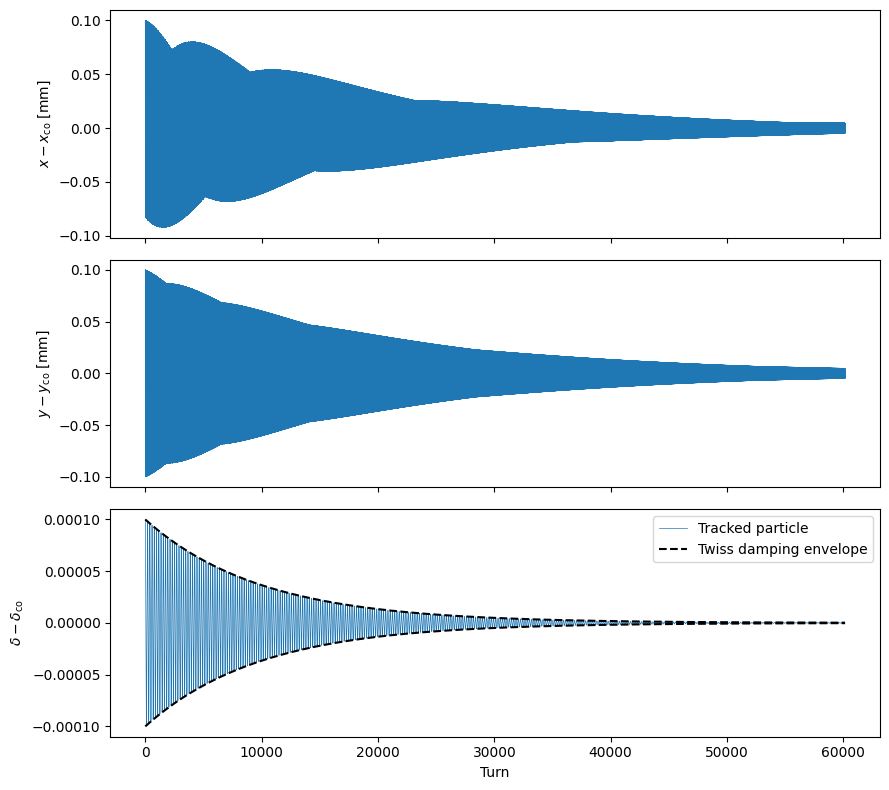

In [9]:
turns = mon.at_turn[0]
x_osc = mon.x[0] - particle_on_co.x[0]
y_osc = mon.y[0] - particle_on_co.y[0]
delta_osc = mon.delta[0] - particle_on_co.delta[0]
envelope = delta_kick * np.exp(-turns / tau_turns[2])

fig, axes = plt.subplots(3, 1, sharex=True, figsize=(9, 8))
axes[0].plot(turns, 1e3 * x_osc, linewidth=0.5)
axes[0].set_ylabel(r'$x-x_{\mathrm{co}}$ [mm]')
axes[1].plot(turns, 1e3 * y_osc, linewidth=0.5)
axes[1].set_ylabel(r'$y-y_{\mathrm{co}}$ [mm]')
axes[2].plot(turns, delta_osc, linewidth=0.5, label='Tracked particle')
axes[2].plot(turns, envelope, 'k--', label='Twiss damping envelope')
axes[2].plot(turns, -envelope, 'k--')
axes[2].set_ylabel(r'$\delta-\delta_{\mathrm{co}}$')
axes[2].set_xlabel('Turn')
axes[2].legend()
plt.tight_layout()